<!-- DRAFT: Graeme to edit -->
# Day 2 · 02 (full data) — Lab: hyperparameter search, round 1 (25 min)

The original lab 02 moves one NHITS setting at a time, then runs a small Optuna search. Here
we tune the N-BEATSx from notebook 01, with its training recipe, on **accuracy only**:

| | |
|---|---|
| Model | N-BEATSx with the 01 recipe and covariates |
| Grid | blocks {1111, 2222} × MLP width {256, 512} × learning rate {2e-4, 4.83e-4, 1e-3} |
| Seeds | 3 per cell (36 fits) |
| Tuned on | the **validation window** (the 14 weeks before the test window) |
| Scored on test | once, for the cell we pick |

Goals

1. Fit every cell of the grid with 3 seeds and score it on the validation window.
2. Measure the **noise floor**: how much the score moves when only the seed changes.
3. Keep a **shortlist** of cells the noise floor cannot separate from the best.
4. Refit the best cell on the full training window and score it on test, once.

Price response waits for round 2 (notebook 05). See `docs/gfm_learnings.md` §6.

**In the chain:** reads `01_recipe`, writes `02_shortlist`.

In [1]:
import itertools

import pandas as pd

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

# The grid: 2 block layouts × 2 widths × 3 learning rates = 12 cells; × 3 seeds = 36 fits.
# Each fit costs about one 01 fit (see `minutes_per_fit` in 01_recipe), so plan for ~36 of
# them on the GPU box. A smoke run fits two cells only.
FULL_GRID = {
    "n_blocks": [[1, 1, 1, 1], [2, 2, 2, 2]],
    "mlp_size": [256, 512],
    "learning_rate": [2e-4, 4.83e-4, 1e-3],
}
SMOKE_GRID = {"n_blocks": [[2, 2, 2, 2]], "mlp_size": [512], "learning_rate": [4.83e-4, 1e-3]}
GRID = SMOKE_GRID if gd.SMOKE else FULL_GRID
MAX_SHORTLIST = 3

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: a score is only a finding if it beats the seed noise

Weigh the same parcel three times on a kitchen scale and the readings differ a little. Two
parcels whose readings differ by less than that are, as far as this scale can tell, the same
weight.

A network is the same. Refit it with a different random seed and the score moves, because
the starting weights and the order of the mini-batches change. That movement is the **noise
floor**. Two settings closer than it are a tie, however good the better one looks. In the
research, seed noise was bigger than many of the effects being chased (§3, [method]), so
every cell here gets three seeds before we compare it with anything.

<!-- DRAFT: Graeme to edit -->
## 1. Data and the starting point

The settings come from `01_recipe`. The training window is split again: the model trains on
the **inner** training weeks and is scored on the 14 validation weeks that follow.
`gp.prepare(cfg, cutoff=bc.VALID_START)` builds that split, with the reference price and the
statics taken from the inner weeks only. RMSSE is scaled by the inner weeks too, so nothing
after `VALID_START` is used until section 5.

In [2]:
recipe_cfg = gd.load_config("01_recipe")
base_params = recipe_cfg["params"]
raw = gd.train_panel()
_, inner, valid, tune_data = gp.prepare(recipe_cfg, panel=raw, cutoff=bc.VALID_START)
panel, train, test, full_data = gp.prepare(recipe_cfg, panel=raw)    # for section 5 only
info = gplt.series_table(panel)

n_series = tune_data.fit_df["unique_id"].nunique()
max_steps = gd.scaled_max_steps(n_series, batch_size=base_params["batch_size"])
print(f"inner train → {inner['ds'].max()} | validation {valid['ds'].min()} → "
      f"{valid['ds'].max()} | {n_series:,} series → {max_steps:,} steps per fit")
pd.Series(base_params)

inner train → 2025-01-01 | validation 2025-01-08 → 2025-04-09 | 17,241 series → 11,718 steps per fit


input_size                                                   14
stack_types           [identity, trend, seasonality, exogenous]
n_blocks                                           [2, 2, 2, 2]
mlp_size                                                    512
mlp_depth                                                     2
n_harmonics                                                   3
n_polynomials                                                 3
dropout_prob_theta                                        0.257
learning_rate                                          0.000483
batch_size                                                  256
scaler_type                                              robust
dtype: object

<!-- DRAFT: Graeme to edit -->
## 2. The grid

Every combination of the grid values, each as a small set of overrides on the 01 settings.
The **incumbent** is the cell with the 01 settings. It is always fitted, because its seeds
set the noise floor.

In [3]:
def grid_cells(grid: dict) -> list[dict]:
    """Every combination of the grid values, as dicts of overrides."""
    names = list(grid)
    cells = []
    for values in itertools.product(*grid.values()):
        cells.append(dict(zip(names, values)))
    return cells


def cell_label(cell: dict) -> str:
    """A short name for a cell, e.g. ``b2222 m512 lr4.8e-04``."""
    blocks = "".join(str(b) for b in cell["n_blocks"])
    return f"b{blocks} m{cell['mlp_size']} lr{cell['learning_rate']:.1e}"


cells = grid_cells(GRID)
incumbent = {name: base_params[name] for name in GRID}
if incumbent not in cells:
    cells.append(incumbent)
cells_by_label = {cell_label(c): c for c in cells}
incumbent_label = cell_label(incumbent)
print(f"{len(cells)} cells × {len(gd.SEEDS)} seeds = {len(cells) * len(gd.SEEDS)} fits | "
      f"incumbent: {incumbent_label}")

12 cells × 3 seeds = 36 fits | incumbent: b2222 m512 lr4.8e-04


<!-- DRAFT: Graeme to edit -->
Each cell's runs are cached under a hash of its full parameter set: a summary and a small loss
curve per seed, and no saved model. If the GPU run crashes, rerun this cell and it picks up
where it stopped.

In [4]:
def fit_cell(cell: dict) -> list[dict]:
    """Three seeds of N-BEATSx with the cell's overrides, trained on the inner window."""
    params = {**base_params, **cell}

    def build(seed):
        return gd.build_nbeatsx(params, tune_data, max_steps, seed, "NBEATSx")

    return gd.fit_seeds(build, tune_data, f"02_cell_{gd.params_key(params)}")


runs = {label: fit_cell(cell) for label, cell in cells_by_label.items()}

2026-11-23 20:16:07,618	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-23 20:16:07,802	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


<!-- DRAFT: Graeme to edit -->
## 3. Validation scores and the noise floor

Each seed is scored on its own: the median RMSSE over the evaluation series. A cell's score
is the mean of its seed medians, and `seed_sd` is how far they spread. The noise floor is the
incumbent's `seed_sd`.

In [5]:
seed_scores = {}
rows = []
for label, cell in cells_by_label.items():
    scores = gd.seed_medians(runs[label], valid, inner)
    health = gd.summaries(runs[label])
    seed_scores[label] = scores
    rows.append({"cell": label,
                 "blocks": "".join(str(b) for b in cell["n_blocks"]),
                 "mlp_size": cell["mlp_size"],
                 "learning_rate": cell["learning_rate"],
                 "median_rmsse_valid": scores.mean(),
                 "seed_sd": scores.std(),
                 "best_seed": scores.min(),
                 "oscillation": health["oscillation"].median(),
                 "best_frac": health["best_frac"].median(),
                 "minutes_per_fit": health["fit_seconds"].mean() / 60})
cell_table = pd.DataFrame(rows).set_index("cell").sort_values("median_rmsse_valid")
noise_floor = cell_table.loc[incumbent_label, "seed_sd"]
print(f"noise floor (seed sd of the incumbent): {noise_floor:.4f}")
cell_table.round(4)

noise floor (seed sd of the incumbent): 0.0048


,blocks,mlp_size,learning_rate,median_rmsse_valid,seed_sd,best_seed,oscillation,best_frac,minutes_per_fit
cell,,,,,,,,,
b2222 m512 lr4.8e-04,2222,512,0.0005,0.6131,0.0048,0.6087,0.0059,0.9469,9.2028
b1111 m512 lr1.0e-03,1111,512,0.0010,0.6229,0.0022,0.6209,0.0130,0.8971,6.2744
b1111 m512 lr4.8e-04,1111,512,0.0005,0.6239,0.0073,0.6174,0.0200,0.9220,5.9306
b2222 m256 lr4.8e-04,2222,256,0.0005,0.6252,0.0005,0.6249,0.0072,0.9220,8.3133
b2222 m512 lr2.0e-04,2222,512,0.0002,0.6257,0.0047,0.6217,0.0038,0.9718,8.9772
b1111 m512 lr2.0e-04,1111,512,0.0002,0.6261,0.0014,0.6251,0.0120,0.7476,6.0350
b1111 m256 lr4.8e-04,1111,256,0.0005,0.6274,0.0164,0.6151,0.0038,0.8472,5.4444
b1111 m256 lr1.0e-03,1111,256,0.0010,0.6327,0.0044,0.6286,0.0082,0.8722,5.7511
b1111 m256 lr2.0e-04,1111,256,0.0002,0.6346,0.0119,0.6221,0.0017,0.9718,5.3806


<!-- DRAFT: Graeme to edit -->
### The grid as a heatmap

Learning rate down the side, architecture across the top. Each square shows the cell's
validation score with its seed spread underneath. Greener is better.

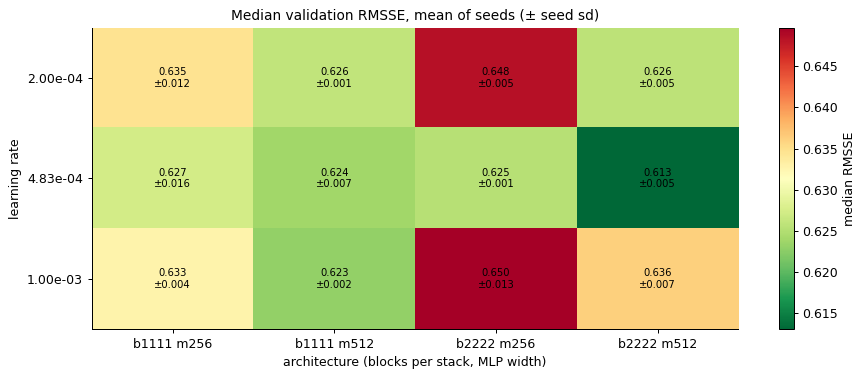

In [6]:
heat = cell_table.assign(arch="b" + cell_table["blocks"] + " m"
                         + cell_table["mlp_size"].astype(str))
means = heat.pivot(index="learning_rate", columns="arch", values="median_rmsse_valid")
sds = heat.pivot(index="learning_rate", columns="arch", values="seed_sd")
cell_text = means.map("{:.3f}".format) + "\n±" + sds.map("{:.3f}".format)
means.index = [f"{lr:.2e}" for lr in means.index]
gplt.plot_heatmap(means, "Median validation RMSSE, mean of seeds (± seed sd)",
                  label="median RMSSE", text=cell_text,
                  figsize=(1.8 * means.shape[1] + 3, 0.9 * means.shape[0] + 1.6),
                  xlabel="architecture (blocks per stack, MLP width)", ylabel="learning rate")

<!-- DRAFT: Graeme to edit -->
### One setting at a time

The original lab moved one setting at a time. The grid gives the same view for free: average
the cells over the other settings, and see how far each setting moves the score. The last
column divides that spread by the noise floor. Below 1 is not a finding.

In [7]:
effects = []
for name in GRID:
    column = "blocks" if name == "n_blocks" else name
    by_value = cell_table.groupby(column)["median_rmsse_valid"].mean()
    spread = by_value.max() - by_value.min()
    effects.append({"setting": name, "best value": by_value.idxmin(), "spread": spread,
                    "spread / noise floor": spread / noise_floor})
pd.DataFrame(effects).set_index("setting").round(4)

,best value,spread,spread / noise floor
setting,,,
n_blocks,1111,0.0051,1.0712
mlp_size,512,0.0117,2.4531
learning_rate,0.000483,0.0130,2.7213


<!-- DRAFT: Graeme to edit -->
## 4. The shortlist

Cells within one noise floor of the best (at most three) form the shortlist. They cannot be
told apart on accuracy. The shortlist is saved in `02_shortlist` as a record; the best cell is
the one that carries forward, and is refitted for the test window below.

Why not simply crown the best cell? The research found that the most accurate trials had the
**weakest** price response (§6, [100k set]). Round 2 (notebook 05) therefore searches on
accuracy and price response together.

In [8]:
best_score = cell_table["median_rmsse_valid"].min()
close = cell_table[cell_table["median_rmsse_valid"] <= best_score + noise_floor]
shortlist = close.head(MAX_SHORTLIST)
best_label = shortlist.index[0]
best_params = {**base_params, **cells_by_label[best_label]}
print(f"best cell: {best_label} | shortlist: {list(shortlist.index)}")
shortlist[["median_rmsse_valid", "seed_sd", "oscillation", "best_frac"]].round(4)

best cell: b2222 m512 lr4.8e-04 | shortlist: ['b2222 m512 lr4.8e-04']


,median_rmsse_valid,seed_sd,oscillation,best_frac
cell,,,,
b2222 m512 lr4.8e-04,0.6131,0.0048,0.0059,0.9469


<!-- DRAFT: Graeme to edit -->
The shortlist and the incumbent side by side, in the arm comparison chart from notebook 01.

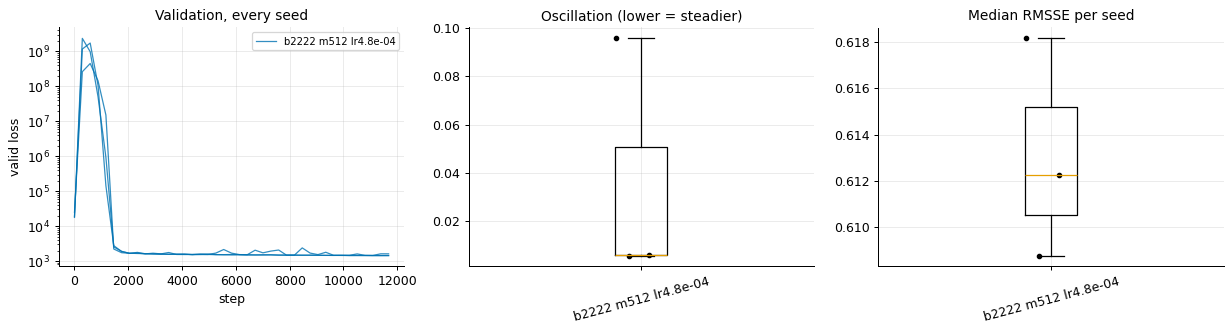

In [9]:
compare = list(shortlist.index)
if incumbent_label not in compare:
    compare.append(incumbent_label)
gplt.plot_arm_comparison({label: runs[label] for label in compare},
                         metrics={label: seed_scores[label] for label in compare})

<!-- DRAFT: Graeme to edit -->
Per-series validation errors of the same cells, from their seed-mean forecasts.

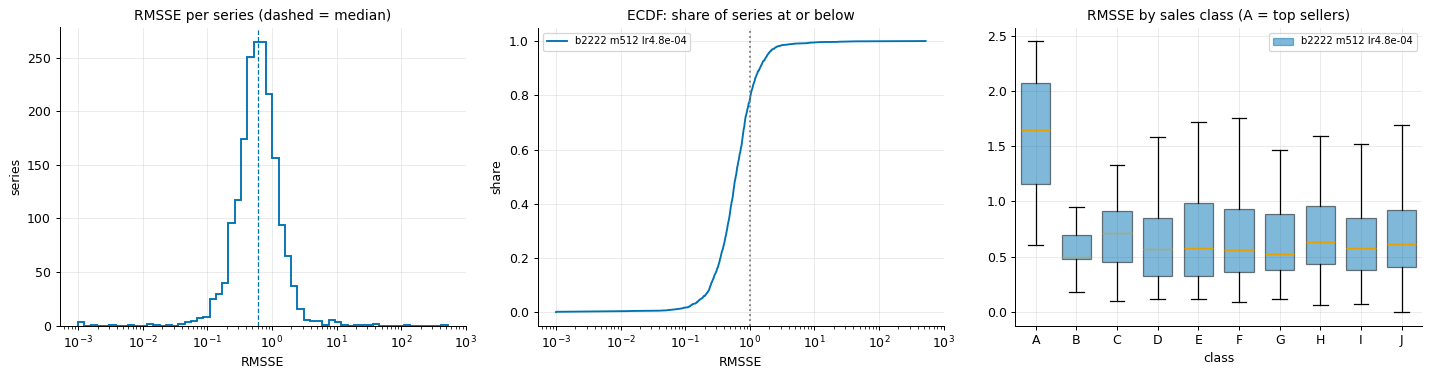

In [10]:
valid_wide = []
for label in compare:
    fcst = gd.seed_forecasts(runs[label])[["unique_id", "ds", "NBEATSx_mean"]]
    fcst = fcst.rename(columns={"NBEATSx_mean": label})
    valid_wide.append(gd.per_series(gd.score(fcst, valid, inner)))
valid_wide = pd.concat(valid_wide, axis=1)
gplt.plot_error_dist(valid_wide, info)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Compare each gap in the heatmap with the noise floor. A cell that wins by less than one
  noise floor is a tie with the incumbent, not a better model.
* Noise floor ≈ __; best cell ≈ __ against the incumbent's ≈ __ (median validation RMSSE).
  <!-- TODO: fill after GPU run -->
* The one-at-a-time table says which settings deserve search budget in round 2. A spread of
  a few noise floors is a real but small effect.
* Check `best_frac` before trusting a cell. If its kept weights come from the very end, it
  wanted more steps, and its score reflects the budget rather than the model.

*Reference run: full panel, GPU box, 3 seeds. Exact numbers vary with seed and hardware; the
reading should not.*

<!-- DRAFT: Graeme to edit -->
## 5. Refit the best cell and score it on test, once

The best cell is refitted on the whole training window with three seeds. It uses the same
series, so the same step budget. The seed-mean forecast goes on the board as `NBEATSx_tuned`.

In [11]:
def nbeatsx_tuned(seed):
    return gd.build_nbeatsx(best_params, full_data, max_steps, seed, "NBEATSx_tuned")


tuned_runs = gd.fit_seeds(nbeatsx_tuned, full_data, "02_nbeatsx_tuned")
tuned = gd.seed_forecasts(tuned_runs)
board_fcst = tuned[["unique_id", "ds", "NBEATSx_tuned_mean"]].rename(
    columns={"NBEATSx_tuned_mean": "NBEATSx_tuned"})
test_seeds = gd.seed_medians(tuned_runs, test, train)
print(f"test median RMSSE per seed: {test_seeds.round(4).to_dict()}")

gd.save_forecasts(board_fcst, "02_tuned")
gd.record(board_fcst, test, train, lab="02 HPO round 1 (3-seed mean)",
          fit_seconds={"NBEATSx_tuned": gd.summaries(tuned_runs)["fit_seconds"].mean()},
          notes=f"best cell on validation: {best_label}; fit_seconds is per seed")
gd.median_board()

test median RMSSE per seed: {'NBEATSx_tuned_s46335': 0.5704, 'NBEATSx_tuned_s11207': 0.579, 'NBEATSx_tuned_s90218': 0.5673}


,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
1,NBEATSx_recipe_mean,0.568,1.114,0.286,1999,01 recipe (3-seed mean),506.900
2,NBEATSx_tuned,0.568,1.114,0.286,1999,02 HPO round 1 (3-seed mean),537.767
3,LightGBM,0.569,1.161,0.295,1999,00 baselines (full panel),NaN
4,AutoETS,0.708,1.285,0.426,1999,00 baselines (full panel),NaN
5,Naive,0.771,1.332,0.470,1999,00 baselines (full panel),NaN
6,NBEATSx_off_mean,0.773,741.411,8.717,1999,01 recipe (3-seed mean),509.233
7,SeasonalNaive,0.929,1.525,0.438,1999,00 baselines (full panel),NaN


<!-- DRAFT: Graeme to edit -->
### Marginal wins over the 01 recipe model

Series by series, does the tuned model beat the untuned recipe model from notebook 01? Read
it with the noise floor in mind: a small median gain can still be many small wins.

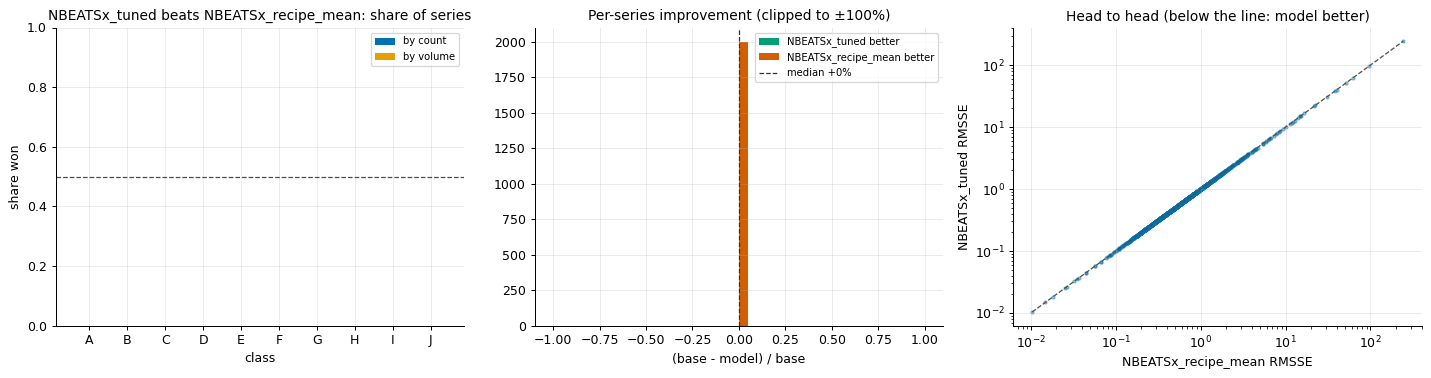

,win_share,win_share_volume,n
sale_class,,,
A,0.0,0.0,4.0
B,0.0,0.0,10.0
C,0.0,0.0,19.0
D,0.0,0.0,31.0
E,0.0,0.0,46.0
F,0.0,0.0,67.0
G,0.0,0.0,96.0
H,0.0,0.0,148.0
I,0.0,0.0,259.0


In [12]:
recipe_fcst = pd.read_parquet(gd.FORECAST_DIR / "01_recipe.parquet")
recipe_fcst = recipe_fcst[["unique_id", "ds", "NBEATSx_recipe_mean"]]
both = board_fcst.merge(recipe_fcst, on=["unique_id", "ds"])
rmsse = gd.per_series(gd.score(both, test, train))
gplt.plot_wins(rmsse, info, model="NBEATSx_tuned", baseline="NBEATSx_recipe_mean")

In [13]:
shortlist_entries = []
for label, row in shortlist.iterrows():
    shortlist_entries.append({"params": {**base_params, **cells_by_label[label]},
                              "median_rmsse_valid": float(row["median_rmsse_valid"]),
                              "seed_sd": float(row["seed_sd"])})
gd.save_config("02_shortlist", {
    "base_params": base_params,
    "grid": GRID,
    "max_steps": max_steps,
    "seeds": gd.SEEDS,
    "noise_floor": float(noise_floor),
    "shortlist": shortlist_entries,
    "best_params": best_params,
    "futr_exog": recipe_cfg["futr_exog"],
    "y_shift": recipe_cfg["y_shift"],
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/02_shortlist.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* **Why not a big search?** Every cell costs three full fits: 12 cells is already 36 fits,
  and an Optuna study of 50 trials would be 150. The noise floor sets how fine a difference
  any search can resolve. Would you spend budget on more trials or more seeds?
* **One at a time hides interactions.** A higher learning rate may suit the small network and
  hurt the large one. Does the heatmap show that? A one-at-a-time sweep could not.
* **Tuning on one window overfits that window.** The research's phase 4 defaults were picked
  on the test window (§1, [method]). Compare the best cell's validation and test scores. If
  test is much worse, how much of the choice was luck?

**Try it:** add `"dropout_prob_theta": [0.1, 0.257]` to `FULL_GRID` and see whether its
spread beats the noise floor. It doubles the number of fits.